# EpiCare: Branch 1, seizure risk forecasting

This notebook walks through Branch 1 end to end with the `epicare_b1` package:

1. **Data**: inspect a My Seizure Gauge archive, preprocess it into 60 s windows, group seizures into events, build the wear mask.
2. **Cycle model**: find each patient's seizure cycles (daily, multiday) from seizure times only.
3. **Wearable model, light version**: the 36 SeFEF hand-made features feeding a personal logistic regression.
4. **Fusion**: the SeFEF prior shift (baseline) against our learned fusion with calibration.
5. **Evaluation**: time-series CV, AUC of sensitivity vs time in warning, Brier skill score, reliability, false alarms per day.
6. **Shared neural network**: self-supervised pretraining, then a supervised step; its hour embeddings replace the hand-made features.
7. **Key experiment**: performance against the number of seizure events seen.
8. **App output**: the hourly JSON of guidelines §4.5, including the prior shift sent to Branch 2.

> **Data mode.** `SYNTHETIC = False` (the default now) runs on the real **My Seizure Gauge** archives in `data/raw/`: at the moment one patient, **Mayo_1869**.
> `SYNTHETIC = True` runs the same code on fake archives that copy the real layout, with known cycles and pre-seizure changes planted in them. Use it to check the code, never to judge performance.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

from epicare_b1 import Config, PatientData
from epicare_b1 import io_msg, preprocessing, plots, pipeline, evaluation
from epicare_b1.models.cycles import CycleModel

SYNTHETIC = False         # <- True: fake archives in data/synthetic (code check only)
cfg = Config()
RAW = ROOT / ("data/synthetic" if SYNTHETIC else "data/raw")
PROCESSED = ROOT / ("data/processed_synth" if SYNTHETIC else "data/processed")
print("raw archives:", RAW, "\nprocessed   :", PROCESSED)

raw archives: c:\Users\moham\OneDrive\Desktop\MCE\ATSN\branch1\data\synthetic 
processed   : c:\Users\moham\OneDrive\Desktop\MCE\ATSN\branch1\data\processed_synth


## 1. Get the data

**Real data**: the Zenodo record 17380899 has 8 archives (3.3–6.9 GB each). Start with the smallest, **Mayo_1869**, as guidelines §3 step 1 says. Put each archive in `data/raw/` as it comes from Zenodo (no need to extract it). The download function resumes after an interruption and checks the md5.

**Synthetic data**: 3 fake patients, 60 days each (about 1–2 minutes per patient).

In [2]:
if SYNTHETIC:
    from epicare_b1.synthetic import make_archive, SynthConfig
    for i, (pid, peak, period) in enumerate([("9001", 15, 7), ("9002", 11, 10), ("9003", 18, 5)]):
        if not (RAW / f"Mayo_{pid}.zip").exists():
            make_archive(RAW, SynthConfig(patient_id=pid, seed=i, peak_hour=peak, multiday_period_d=period))
else:
    # io_msg.download_archive("1869", RAW)      # 3.3 GB, uncomment to download
    pass
archives = sorted(RAW.glob("Mayo_*.zip"))
archives

[WindowsPath('c:/Users/moham/OneDrive/Desktop/MCE/ATSN/branch1/data/synthetic/Mayo_9001.zip'),
 WindowsPath('c:/Users/moham/OneDrive/Desktop/MCE/ATSN/branch1/data/synthetic/Mayo_9002.zip'),
 WindowsPath('c:/Users/moham/OneDrive/Desktop/MCE/ATSN/branch1/data/synthetic/Mayo_9003.zip')]

### 1.1 Look inside an archive *before* writing anything else

The Zenodo preview shows `Mayo_<id>/<id>.txt` plus about 170 nested zips named `<unix start>_<device serial>.zip`. That naming is how Empatica E4 Connect exports a session (ACC/BVP/EDA/HR/TEMP CSVs: row 1 = start time, row 2 = sampling rate).
`inspect_archive` prints the first lines of every file, so you can confirm this on the real data. The seizure file's format is checked here as well.

In [3]:
report = io_msg.inspect_archive(archives[0], n_sessions=2)

Mayo_9001.zip: 67 files, 66 session zips
devices: {'A0F001': 35, 'A0F002': 30, '000000': 1}
non-session files: ['Mayo_9001/9001.txt']

--- Mayo_9001/9001.txt (first lines) ---
1579586033
1583216302
1582825549
1583108993
1579706565
1583253913
1579372047
1578871905
parsed 66 onsets, 2020-01-07 08:19:50+00:00 -> 2020-03-17 03:13:16+00:00

=== Mayo_9001/1578290400_000000.zip  (start 2020-01-06 06:00:00+00:00) ===
  steps.json               2 B | []

=== Mayo_9001/1578323677_A0F001.zip  (start 2020-01-06 15:14:37+00:00) ===
  ACC.csv          1,061,818 B | 1578323677.000000,1578323677.000000,1578323677.000000 | 4.000000,4.000000,4.000000 | 1,0,66 | 0,-2,64
  BVP.csv          1,629,558 B | 1578323677.000000 | 8.000000 | 33.66 | 39.41
  EDA.csv            898,219 B | 1578323677.000000 | 4.000000 | 1.9381 | 1.9381
  HR.csv             192,136 B | 1578323687.000000 | 1.000000 | 64.87 | 64.09
  TEMP.csv           768,947 B | 1578323677.000000 | 4.000000 | 32.6 | 32.6
  IBI.csv                 23

### 1.2 Preprocess: windows, wear mask, features

For each session: ACC magnitude, BVP band-pass 1–7 Hz, EDA low-pass and smoothing, then 60 s windows aligned on the minute.
A window is kept only if ACC, BVP, EDA and HR each cover ≥ 80 % of it and the watch is on the skin (temperature ≥ 25 °C, EDA ≥ 0.02 µS). **Missing windows are absent, never treated as calm.**
Each window stores the 36 SeFEF features and a compact 1 Hz raw window (6 channels) for the neural network. Where both devices overlap in time, the window with better coverage is kept.
Mayo_1869 has 182 sessions and takes about 12 minutes on a laptop; the result is cached in `data/processed/1869/`, so this runs once. `max_sessions=` gives a quick trial.

In [4]:
for a in archives:
    pid = io_msg.Archive(a).patient_id
    if not (PROCESSED / pid / "windows.npz").exists():
        preprocessing.process_archive(a, cfg, PROCESSED)        # add max_sessions=10 for a quick try
P = pipeline.load_patients(PROCESSED, cfg=cfg)
pd.DataFrame([d.summary() for d in P.values()])

,patient,days,worn_fraction,n_seizures,n_events,events_in_recording,pos_rate_1h,pos_rate_24h
0,9001,74.3,0.332,66,38,38,0.0213,0.3845
1,9002,73.3,0.373,69,40,40,0.0227,0.4517
2,9003,74.3,0.347,60,39,38,0.0213,0.4275


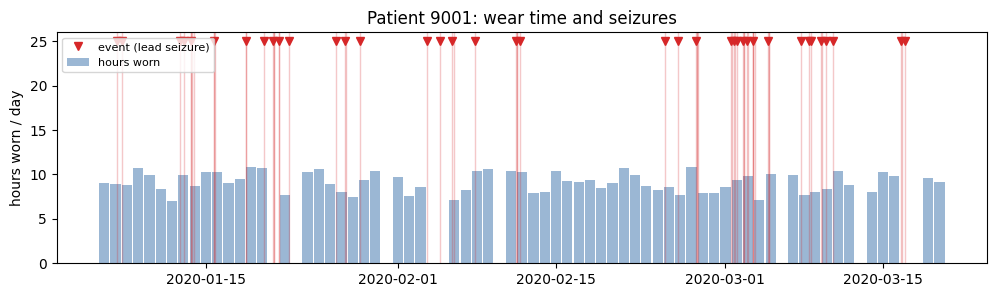

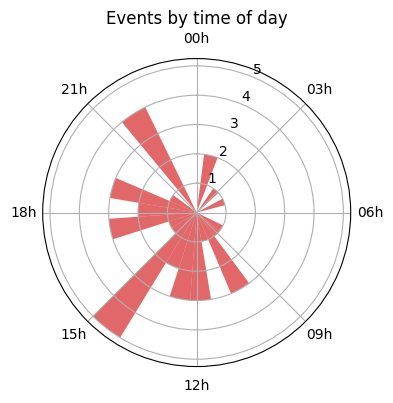

{'n_seizures': 66,
 'n_events': 38,
 'first': '2020-01-07 08:19:50+00:00',
 'last': '2020-03-17 03:13:16+00:00',
 'span_days': 69.8,
 'events_per_day': 0.545,
 'event_hour_local_hist': [2,
  0,
  1,
  0,
  1,
  0,
  0,
  0,
  1,
  2,
  2,
  3,
  3,
  3,
  5,
  1,
  1,
  3,
  2,
  3,
  1,
  0,
  4,
  0]}

In [5]:
pid = list(P)[0]; d = P[pid]
plots.plot_wear_and_seizures(d); plt.show()
fig = plt.figure(figsize=(4, 4)); plots.plot_seizure_clock(d, fig.add_subplot(projection="polar")); plt.show()
from epicare_b1.seizures import summarize_seizures
summarize_seizures(d.seizures, cfg.label.event_gap_h, cfg.local_tz)

## 2. Personal cycle model (seizure times only)

Candidate periods: 12 h and 24 h (local time) and 3–45 days. A period is tested only if the training span holds ≥ 3 full periods.
Each period gets a Rayleigh test, and the kept cycles (Bonferroni-corrected, harmonics removed) get a von Mises fit. Risk follows a Poisson process whose rate is modulated by the cycle phases.

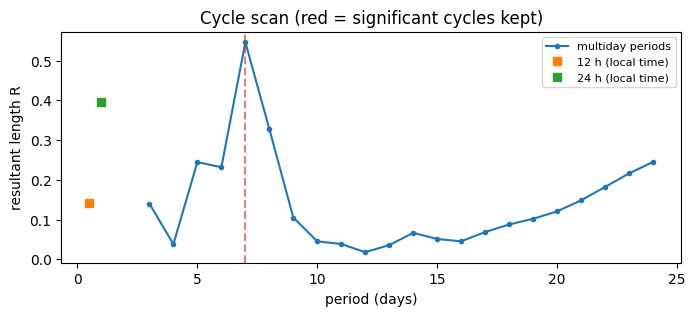

{'base_rate_per_day': 0.518,
 'cycles': [{'period': '7.0 d',
   'R': 0.546,
   'p': 5.3e-06,
   'kappa': 1.31,
   'peak': '7.0 d cycle, peak at phase 0.72'}]}

In [6]:
cm = CycleModel(cfg.cycle, cfg.local_tz).fit(d.events, d.hours[0], d.hours[-1])
plots.plot_cycle_scan(cm); plt.show()
cm.summary()

## 3–5. Light version: SeFEF features + personal layer + fusion, with time-series CV

Folds use an expanding window: the first third of the recording trains, the next block (half that length) tests, then the window grows. Every train and test set holds at least 3 events.
For every fold the per-hour-of-day normaliser, the cycle model, the personal layer and the fusion are refitted **on the past only**.

| model | what it is |
|---|---|
| `base` | always the training-period event rate (Brier skill reference) |
| `cycle` | personal cycle model alone (SeFEF "vMe", best published model, hourly AUC 0.66) |
| `wear` | personal logistic regression on the wearable features (SeFEF "LR") |
| `prior_shift` | `wear` with its intercept shifted by the cycle log-odds (SeFEF "LR-vMe") |
| `epicare` | **ours**: learned fusion of wear + cycle + time since the last seizure, fitted on the latest 30 % of training (also calibrates) |

In [7]:
res_feat, summ_feat, fitted_feat = pipeline.run_branch1(P, cfg, "features")
summ_feat

[9001] 3 folds
  fold 0: train events 14, 1h AUC 0.97 BSS +0.208, 24h AUC 0.48 BSS -0.221
  fold 1: train events 20, 1h AUC 0.62 BSS -0.014, 24h AUC 0.50 BSS -1.013
  fold 2: train events 28, 1h AUC 0.84 BSS +0.125, 24h AUC 0.68 BSS +0.213
[9002] 4 folds
  fold 0: train events 11, 1h AUC 0.42 BSS -0.643, 24h AUC 0.58 BSS -0.066
  fold 1: train events 17, 1h AUC 0.75 BSS +0.041, 24h AUC 0.58 BSS +0.158
  fold 2: train events 24, 1h AUC 0.78 BSS +0.090, 24h AUC 0.59 BSS -0.345
  fold 3: train events 30, 1h AUC 0.83 BSS +0.081, 24h AUC 0.35 BSS -0.487
[9003] 4 folds
  fold 0: train events 13, 1h AUC 0.92 BSS -0.023, 24h AUC 0.45 BSS -0.562
  fold 1: train events 21, 1h AUC 0.86 BSS +0.038, 24h AUC 0.66 BSS -0.562
  fold 2: train events 27, 1h AUC 0.71 BSS -0.333, 24h AUC 0.52 BSS -1.044
  fold 3: train events 33, 1h AUC 0.67 BSS +0.409, 24h AUC 0.64 BSS +0.063


AUC_TiW_mean  AUC_TiW_std  AUC_TiW_count  BSS_mean  BSS_std  BSS_count  FA_per_day_mean  FA_per_day_std  FA_per_day_count
horizon_h model                                                                                                                                 
1         base                0.500        0.000              3     0.000    0.000          3            0.000           0.000                 3
          cycle               0.699        0.101              3     0.019    0.013          3            0.621           0.933                 3
          epicare             0.765        0.062              3     0.007    0.108          3            1.416           0.740                 3
          prior_shift         0.794        0.082              3     0.058    0.109          3            1.816           0.760                 3
          wear                0.754        0.091              3     0.034    0.111          3            2.159           0.531                 3
24        base                0.500        0.000              3     0.000    0.000          3            0.000           0.000                 3
          cycle               0.602        0.079              3     0.124    0.108          3            0.021           0.022                 3
          epicare             0.549        0.020              3    -0.350    0.171          3            0.093           0.018                 3
          prior_shift         0.565        0.089              3    -0.528    0.148          3            0.081           0.058                 3
          wear                0.507        0.043              3    -0.636    0.183          3            0.101           0.028                 3

In [8]:
pipeline.compare_with_sefef(summ_feat)

,horizon,model,our_AUC,our_BSS,SeFEF_vMe_AUC,SeFEF_LR_AUC
0,hourly,base,0.500,0.000,0.66,0.5
1,hourly,cycle,0.699,0.019,0.66,0.5
2,hourly,epicare,0.765,0.007,0.66,0.5
3,hourly,prior_shift,0.794,0.058,0.66,0.5
4,hourly,wear,0.754,0.034,0.66,0.5
5,daily,base,0.500,0.000,0.47,0.4
6,daily,cycle,0.602,0.124,0.47,0.4
7,daily,epicare,0.549,-0.350,0.47,0.4
8,daily,prior_shift,0.565,-0.528,0.47,0.4
9,daily,wear,0.507,-0.636,0.47,0.4


In [9]:
# per patient (report every patient, including failures)
res_feat.groupby(["patient", "horizon_h", "model"])[["AUC_TiW", "BSS", "FA_per_day"]].mean().unstack("model").round(3)

AUC_TiW                                    BSS                                   FA_per_day                                  
model                base  cycle epicare prior_shift   wear base  cycle epicare prior_shift   wear       base  cycle epicare prior_shift   wear
patient horizon_h                                                                                                                              
9001    1             0.5  0.804   0.810       0.864  0.812  0.0  0.031   0.106       0.169  0.098        0.0  0.049   0.930       0.957  1.546
        24            0.5  0.655   0.553       0.658  0.556  0.0  0.186  -0.340      -0.498 -0.790        0.0  0.019   0.075       0.019  0.079
9002    1             0.5  0.690   0.694       0.705  0.649  0.0  0.022  -0.108      -0.049 -0.095        0.0  1.698   1.050       2.404  2.466
        24            0.5  0.511   0.528       0.480  0.480  0.0 -0.000  -0.185      -0.689 -0.685        0.0  0.000   0.093       0.133  0.133
9003    1             0.5  0.602   0.790       0.813  0.801  0.0  0.005   0.023       0.053  0.098        0.0  0.116   2.268       2.087  2.465
        24            0.5  0.639   0.567       0.556  0.486  0.0  0.186  -0.526      -0.398 -0.433        0.0  0.044   0.110       0.091  0.091

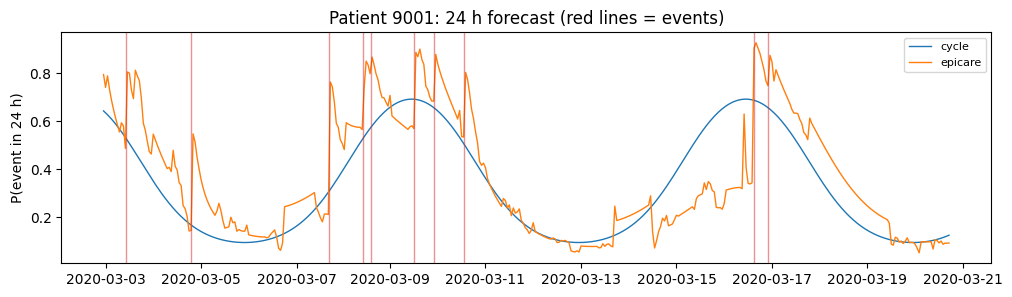

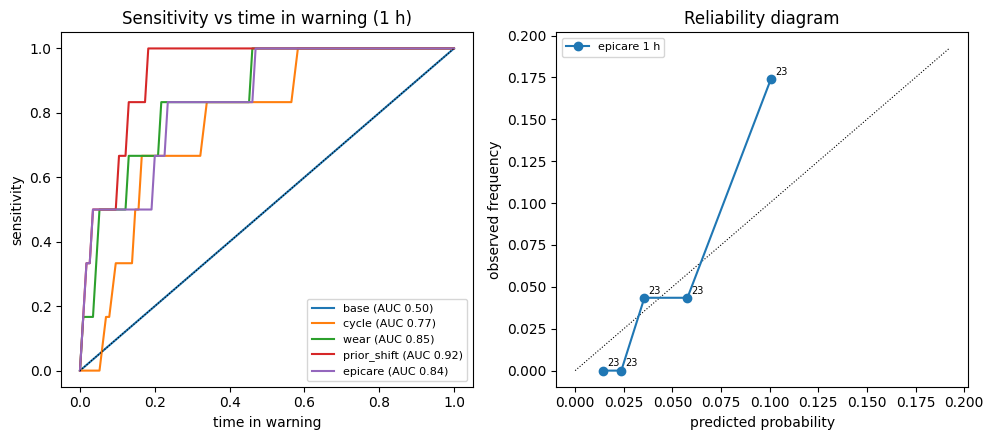

In [10]:
# predictions of the last fold for one patient
k, f_last, pred = fitted_feat[pid][-1]
plots.plot_forecast(pred, d, horizon=24); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
worn = pred["worn"].to_numpy() & ~d.post_ictal[np.searchsorted(d.hours, pred["time"].astype("int64") // 10**9)]
plots.plot_sen_tiw(pred, 1, mask=worn, ax=ax[0])
plots.plot_reliability(pred["epicare_1h"][worn], pred["y_1h"][worn], ax=ax[1], label="epicare 1 h")
plt.tight_layout(); plt.show()

## 6. Shared neural network (all patients)

- **Input**: per 60 s window, 6 channels at 1 Hz (movement mean/std, BVP amplitude, EDA, HR, temperature), normalised per patient and hour of day, plus the 36 features.
- **Architecture**: a 1D CNN per window, then a masked mean into 5-minute tokens (with a learned *missing* token for gaps), then a bidirectional GRU over the last 4 h, giving a 32-d hour embedding plus time of day.
- **Training**: masked-token reconstruction (self-supervised, every worn hour, no labels), then a light supervised step on pre-seizure labels.

To keep it honest, each patient's network training uses only data **before that patient's first test fold**. `pipeline.leave_one_patient_out` runs the stricter new-patient test.
With a single real patient the "shared" network is trained on that patient only, so this section tests the architecture, not the benefit of learning across patients. Epochs are kept small so the notebook runs on CPU in a few minutes; raise `cfg.net.*_epochs` and `max_hours_per_patient` (or use a GPU) once several patients are processed.

In [11]:
cfg.net.pretrain_epochs = 2 if SYNTHETIC else 5
cfg.net.finetune_epochs = 2 if SYNTHETIC else 3
cfg.net.max_hours_per_patient = 800 if SYNTHETIC else 2000
model, batcher, hist = pipeline.train_shared_network(P, cfg)
res_sh, summ_sh, fitted_sh = pipeline.run_branch1(P, cfg, "shared", model, batcher, verbose=False)
summ_sh

c:\Users\moham\OneDrive\Desktop\MCE\ATSN\branch1\epicare_b1\models\shared_net.py:192: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  loss_sum += float(loss)


pretrain epoch 1/2: recon loss 0.8126 (635 hours, 8s)
pretrain epoch 2/2: recon loss 0.6833 (635 hours, 7s)
finetune epoch 1/2: loss 0.7978 (255 positive / 586 usable hours)
finetune epoch 2/2: loss 0.6916 (255 positive / 586 usable hours)


AUC_TiW_mean  AUC_TiW_std  AUC_TiW_count  BSS_mean  BSS_std  BSS_count  FA_per_day_mean  FA_per_day_std  FA_per_day_count
horizon_h model                                                                                                                                 
1         base                0.500        0.000              3     0.000    0.000          3            0.000           0.000                 3
          cycle               0.699        0.101              3     0.019    0.013          3            0.621           0.933                 3
          epicare             0.684        0.061              3    -0.020    0.071          3            1.254           0.281                 3
          prior_shift         0.719        0.066              3     0.042    0.004          3            1.794           0.606                 3
          wear                0.645        0.035              3     0.017    0.012          3            2.579           0.372                 3
24        base                0.500        0.000              3     0.000    0.000          3            0.000           0.000                 3
          cycle               0.602        0.079              3     0.124    0.108          3            0.021           0.022                 3
          epicare             0.508        0.029              3    -0.149    0.067          3            0.057           0.030                 3
          prior_shift         0.569        0.123              3    -0.107    0.032          3            0.028           0.014                 3
          wear                0.471        0.048              3    -0.321    0.127          3            0.015           0.025                 3

In [12]:
both = pd.concat({"features": summ_feat["AUC_TiW_mean"], "shared net": summ_sh["AUC_TiW_mean"]}, axis=1)
both

features  shared net
horizon_h model                            
1         base            0.500       0.500
          cycle           0.699       0.699
          epicare         0.765       0.684
          prior_shift     0.794       0.719
          wear            0.754       0.645
24        base            0.500       0.500
          cycle           0.602       0.602
          epicare         0.549       0.508
          prior_shift     0.565       0.569
          wear            0.507       0.471

## 7. Key experiment: performance vs number of events seen

Training uses data up to the *n*-th event and testing covers the following period (20 days on the synthetic data, 60 days on the real data, where events are about 8 times rarer). With 0 events the forecast is the base rate (or the shared network, once trained on other patients); the personal parts switch on at 5 events (cycles) and 10 events (personal layer, learned fusion).

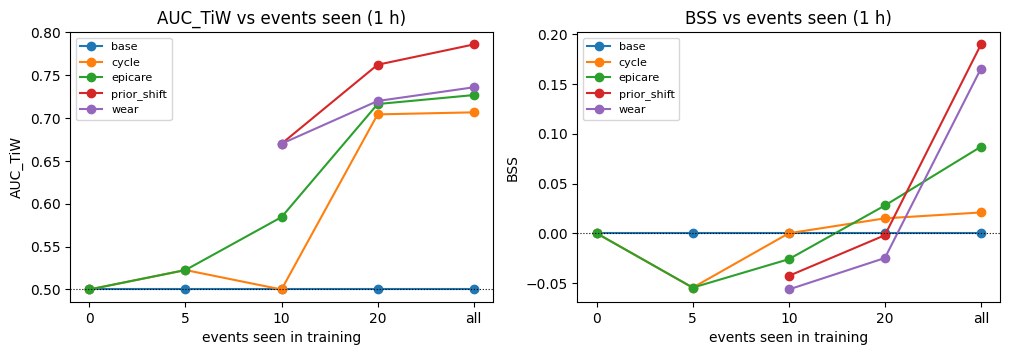

In [13]:
curve = pd.concat([evaluation.events_seen_curve(dd, cfg, test_days=20 if SYNTHETIC else 60) for dd in P.values()], ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plots.plot_events_seen(curve, 1, ax=ax[0]); plots.plot_events_seen(curve, 1, "BSS", ax=ax[1]); plt.show()

## 8. Final model and the hourly output for the app and for Branch 2

`fit_final` trains on all available data (as for deployment or the demo replay). `hourly_output` returns the JSON of guidelines §4.5.
`prior_shift_for_detector = clip(log(r / r̄), -1, 1)` is the value Branch 2 adds to its logit (§5.5).

{
 "time": "2020-03-19T07:00",
 "horizon": "24h",
 "probability": 0.271,
 "probability_next_hour": 0.0028,
 "baseline_probability": 0.404,
 "level": "low",
 "prior_shift_for_detector": -1.0,
 "drivers": [
  "eda d2 unusual (last 6 h)",
  "eda peak amp sum unusual (last 24 h)"
 ],
 "confidence": "high",
 "message": "About 3 days in 10 like today have a seizure"
}


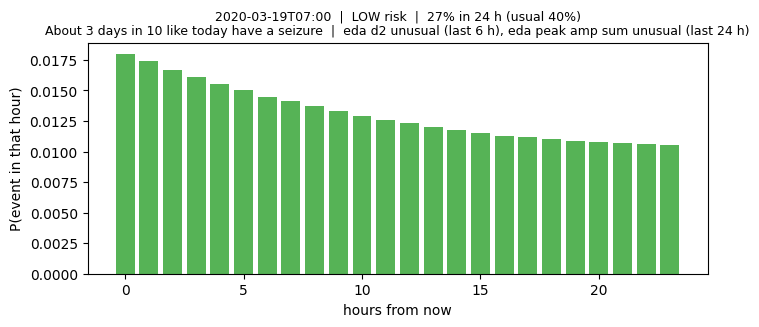

{'n_training_events': 38,
 'base_rate_per_day': 0.518,
 'cycles': [{'period': '7.0 d',
   'R': 0.546,
   'p': 5.3e-06,
   'kappa': 1.31,
   'peak': '7.0 d cycle, peak at phase 0.72'}],
 'fusion': {1: ('learned',
   {'coef': [1.051, 1.325, 0.536], 'intercept': 4.451}),
  24: ('learned', {'coef': [-0.416, 1.739, 0.182], 'intercept': 0.546})},
 'levels': {'low_below': 0.3434727993707913, 'high_above': 0.8840093781256999}}

In [14]:
final = pipeline.fit_final(d, cfg)
X, names = d.hourly_features()
i = len(d.hours) - 36                     # replay an hour near the end of the recording
out = final.hourly_output(d, i, X)
print(json.dumps({k: v for k, v in out.items() if k != "profile_24h"}, indent=1))
plots.plot_risk_card(out); plt.show()
final.doctor_summary()

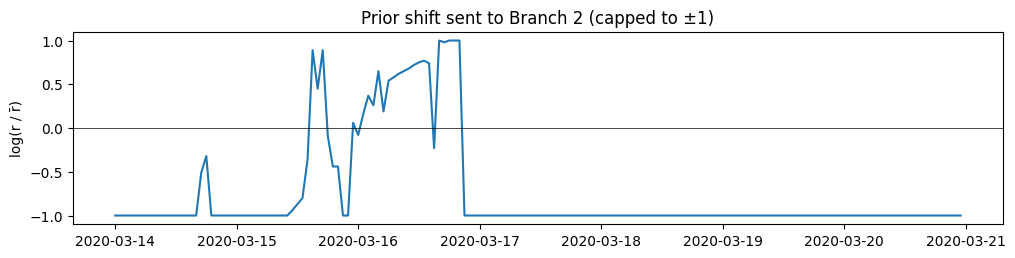

In [15]:
# prior shift over one week, as Branch 2 would receive it
week = range(len(d.hours) - 24 * 7, len(d.hours))
shift = [final.hourly_output(d, j, X)["prior_shift_for_detector"] for j in week]
plt.figure(figsize=(12, 2.5)); plt.plot(pd.to_datetime(d.hours[list(week)], unit="s"), shift)
plt.axhline(0, color="k", lw=0.5); plt.ylabel("log(r / r̄)"); plt.title("Prior shift sent to Branch 2 (capped to ±1)"); plt.show()

In [16]:
# save the trained parts
(ROOT / "models").mkdir(exist_ok=True)
pipeline.save_forecaster(final, ROOT / "models" / f"forecaster_{pid}.pkl")
from epicare_b1.models import shared_net as sn
sn.save(model, ROOT / "models" / "shared_net.pt")
(ROOT / "results").mkdir(exist_ok=True)
res_feat.to_csv(ROOT / "results" / "folds_features.csv", index=False)
res_sh.to_csv(ROOT / "results" / "folds_shared.csv", index=False)
# SeFEF input file (needs `pip install h5py`; sefef itself is optional)
try:
    from epicare_b1.sefef_export import write_sefef_h5
    print(write_sefef_h5(preprocessing.load_processed(PROCESSED / pid), ROOT / "data" / "sefef" / f"{pid}.h5"))
except ImportError as e:
    print("SeFEF export skipped:", e)

SeFEF export skipped: No module named 'h5py'


## Adding the other patients

1. Put each archive in `data/raw/` (`python -m epicare_b1 download <id>`; 3.3 to 6.9 GB each).
2. Run **1.1 inspect** on it to check it has the same layout as Mayo_1869 (E4 CSVs in nested zips, `<id>.txt` with Unix onsets).
3. Rerun the notebook: preprocessing skips patients already in `data/processed/`.
4. Compare with SeFEF on its six patients 1110, 1869, 1876, 1904, 1965, 2002 (milestone M1 gate), then add 1927 and 1988.
5. With several patients, train the shared network on all of them and run `pipeline.leave_one_patient_out` for the new-patient test.

## 9. Checks behind the conclusions

Cycles found on all of each patient's data, fold-by-fold wins (an average over a few folds hides a lot of variation), and how many positive hours or days each test set holds. On synthetic data the planted truth is printed next to what the model found.

In [ ]:
# Supporting numbers for the conclusions below (uses P, cfg, res_feat and res_sh from above)
planted = {"9001": (15, 7), "9002": (11, 10), "9003": (18, 5)} if SYNTHETIC else {}   # synthetic truth
print("== Cycles found on all data ==")
for p_id, dd in P.items():
    cmod = CycleModel(cfg.cycle, cfg.local_tz).fit(dd.events, dd.hours[0], dd.hours[-1])
    kept = [f"{c['period']} (p={c['p']:.1e})" for c in cmod.summary()["cycles"]] or ["none"]
    t24 = [r for r in cmod.tested if r["local"] and r["period_h"] == 24][0]
    peak = (t24["mu"] % (2 * np.pi)) / (2 * np.pi) * 24
    truth = f" | planted: 24 h peak {planted[p_id][0]} h + {planted[p_id][1]} d" if p_id in planted else ""
    print(f"{p_id}: {len(dd.events)} events | kept: {', '.join(kept)} | "
          f"24 h test: R={t24['R']:.2f} p={t24['p']:.1e}, mean hour ~{peak:.1f} h local{truth}")

for name, r in [("features", res_feat), ("shared net", res_sh)]:
    print(f"\n== {name}: fold-by-fold comparison ({r.groupby(['patient', 'fold']).ngroups} folds) ==")
    for h in (1, 24):
        w = r[r.horizon_h == h].pivot_table(index=["patient", "fold"], columns="model", values=["AUC_TiW", "BSS"])
        a, b = w["AUC_TiW"], w["BSS"]
        print(f"h={h:>2}: epicare>prior_shift AUC {int((a.epicare > a.prior_shift).sum())}/{len(a)}, "
              f"epicare>cycle AUC {int((a.epicare > a.cycle).sum())}/{len(a)}, "
              f"wear>cycle AUC {int((a.wear > a.cycle).sum())}/{len(a)}, "
              "BSS>0: " + ", ".join(f"{m} {int((b[m] > 0).sum())}" for m in ["cycle", "wear", "prior_shift", "epicare"]))

print("\ntest-set size per fold (1 h: worn hours, 24 h: days) and positives:")
print(res_feat[res_feat.model == "base"].groupby("horizon_h")[["n_test", "n_pos"]].agg(["min", "median", "max"]).to_string())

## 10. Conclusions

*(filled in after the run on Mayo_1869)*